### Imports and Preprocessing

In [ ]:
pip install umap-learn

In [ ]:
pip install tensorflow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from umap import UMAP
from sklearn.metrics import f1_score
import tensorflow as tf
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model

In [ ]:
X = pd.read_csv('/content/drive/MyDrive/Honors/U2OS.csv')
X

<ipython-input-6-50f9cd3cd88b>:1: DtypeWarning: Columns (1800,1801,1802,1803) have mixed types. Specify dtype option on import or set low_memory=False.
  X = pd.read_csv('/content/drive/MyDrive/Honors/U2OS.csv')


,Metadata_Plate,Metadata_Well,Metadata_Assay_Plate_Barcode,Metadata_Plate_Map_Name,Metadata_well_position,Metadata_ASSAY_WELL_ROLE,Metadata_broad_sample,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,...,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,Metadata_pert_iname,Metadata_pert_iname2,Metadata_moa,Metadata_target,Metadata_mmoles_per_liter2,Metadata_Sample_Dose,pert_type,control_type
0,24277,a01,24277,H-BIOA-004-3,a01,treated,BRD-K18250272-003-03-7,3.022516,DMSO,BRD-K18250272,...,2.376336,2.402145,propoxycaine,propoxycaine,local anesthetic,NaN,6.05,BRD-K18250272-003-03-7_6.05,trt,NaN
1,24277,a02,24277,H-BIOA-004-3,a02,treated,BRD-K18316707-001-01-9,5.000000,DMSO,BRD-K18316707,...,2.428562,2.458853,O-1918,BRD-K18316707,cannabinoid receptor antagonist,NaN,10.00,BRD-K18316707-001-01-9_10.0,trt,NaN
2,24277,a03,24277,H-BIOA-004-3,a03,treated,BRD-K18438502-001-02-6,5.000000,DMSO,BRD-K18438502,...,2.431198,2.479527,NaN,NaN,NaN,NaN,10.00,BRD-K18438502-001-02-6_10.0,trt,NaN
3,24277,a04,24277,H-BIOA-004-3,a04,treated,BRD-K18550767-001-02-8,5.000000,DMSO,BRD-K18550767,...,2.529105,2.598130,bergenin,bergenin,interleukin inhibitor,"IL1B, TNF",10.00,BRD-K18550767-001-02-8_10.0,trt,NaN
4,24277,a05,24277,H-BIOA-004-3,a05,treated,BRD-K18574842-323-03-3,2.195487,DMSO,BRD-K18574842,...,2.590156,2.649836,nafcillin,nafcillin,bacterial cell wall synthesis inhibitor,"CYP1A2, CYP3A4, SLC22A6",4.39,BRD-K18574842-323-03-3_4.39,trt,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153381,26795,p20,26795,H-CBLD-004-4,p20,treated,BRD-K17405724-001-01-0,4.916061,DMSO,BRD-K17405724,...,2.195413,2.259248,NaN,NaN,NaN,NaN,9.83,BRD-K17405724-001-01-0_9.83,trt,NaN
153382,26795,p21,26795,H-CBLD-004-4,p21,treated,BRD-K90170141-001-01-5,4.859274,DMSO,BRD-K90170141,...,2.223356,2.237415,NaN,NaN,NaN,NaN,9.72,BRD-K90170141-001-01-5_9.72,trt,NaN
153383,26795,p22,26795,H-CBLD-004-4,p22,treated,BRD-K45307499-001-01-7,5.109445,DMSO,BRD-K45307499,...,2.195292,2.240176,NaN,NaN,NaN,NaN,10.22,BRD-K45307499-001-01-7_10.22,trt,NaN
153384,26795,p23,26795,H-CBLD-004-4,p23,treated,BRD-K84521261-001-01-1,4.958284,DMSO,BRD-K84521261,...,2.277124,2.300320,NaN,NaN,NaN,NaN,9.92,BRD-K84521261-001-01-1_9.92,trt,NaN


In [ ]:
X[['Metadata_Well','Nuclei_Texture_Variance_RNA_3_0','Cells_Intensity_MeanIntensity_DNA','Metadata_pert_iname',
   'Metadata_moa']][:5]

,Metadata_Well,Nuclei_Texture_Variance_RNA_3_0,Cells_Intensity_MeanIntensity_DNA,Metadata_pert_iname,Metadata_moa
0,a01,2.376336,0.004146,propoxycaine,local anesthetic
1,a02,2.428562,0.004474,O-1918,cannabinoid receptor antagonist
2,a03,2.431198,0.004582,NaN,NaN
3,a04,2.529105,0.004177,bergenin,interleukin inhibitor
4,a05,2.590156,0.004347,nafcillin,bacterial cell wall synthesis inhibitor


In [ ]:
X.columns[:20]

In [ ]:
X.columns[-20:]

### Date Substitution

In [ ]:
date_list = []
for i in X[X.columns[3]]:
  if(i==('C-2113-01-D39-008')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-009')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-010')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-011')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-012')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-013')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-014')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-015')):
    date_list.append('May 24th, 2011')
  if(i==('C-2113-01-D39-001')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-002')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-003')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-004')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-005')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-006')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-007')):
    date_list.append('April 29th, 2011')
  if(i==('C-2113-01-D39-025')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-026')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-027')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-028')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-029')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-030')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-031')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-032')):
    date_list.append('June 13th, 2011')
  if(i==('C-2113-01-D39-016')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-017')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-018')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-019')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-020')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-021')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-022')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-023')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-D39-024')):
    date_list.append('June 21st, 2011')
  if(i==('C-2113-01-CMP-002')):
    date_list.append('June 21st, 2011')
  if(i==('H-BIOA-001-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-002-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-003-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-004-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-005-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-006-3')):
    date_list.append('April 21st, 2011')
  if(i==('H-BIOA-007-3')):
    date_list.append('April 29th, 2011')
  if(i==('H-CBLA-001-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-002-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-003-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-004-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-005-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-006-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLA-007-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLB-001-4')):
    date_list.append('March 16th, 2011')
  if(i==('H-CBLE-005-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLE-006-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLE-007-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLE-008-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLE-009-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLE-010-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLH-005-4')):
    date_list.append('April 21st, 2011')
  if(i==('H-CBLF-001-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLF-002-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLF-003-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLG-001-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLG-002-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLG-003-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLG-004-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLG-005-4')):
    date_list.append('April 11th, 2011')
  if(i==('H-CBLC-005-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLC-006-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLC-007-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLB-006-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLE-001-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLE-002-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLE-003-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLE-004-4')):
    date_list.append('March 23rd, 2011')
  if(i==('H-CBLG-006-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLG-007-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLG-008-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLG-009-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLG-010-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLH-001-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLH-002-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLH-003-4')):
    date_list.append('April 19th, 2011')
  if(i==('H-CBLC-001-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLC-002-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLC-003-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLC-004-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLB-002-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLB-003-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLB-004-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLB-005-4')):
    date_list.append('March 21st, 2011')
  if(i==('H-CBLD-001-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLD-002-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLD-003-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLD-004-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLP-001-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLP-002-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLH-007-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLJ-001-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLJ-002-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLO-001-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLO-002-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLN-001-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLN-002-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLH-006-4')):
    date_list.append('August 9th, 2011')
  if(i==('H-CBLK-001-4')):
    date_list.append('August 9th, 2011')

In [ ]:
X['Date']=date_list

### Projection Pursuit

In [ ]:
X.groupby('Date', group_keys=False).apply(lambda x: x.sample(frac=0.2)).to_csv('/content/drive/MyDrive/Honors/X_samp.csv')

In [ ]:
X_sample = pd.read_csv('/content/drive/MyDrive/Honors/X_sample.csv')

In [ ]:
X_sample

,Unnamed: 0,Projection 1,Projection 2,Projection 1.1,Projection 2.1,Projection 1.2,Projection 2.2
0,1,-0.340215,-0.101073,0.704157,1.065219,-0.701039,1.156685
1,2,-0.124787,0.486776,-1.804943,0.979902,-0.528835,1.925674
2,3,0.172445,-0.287923,-1.408593,0.453910,-0.346240,1.638055
3,4,-0.129310,-0.711580,-1.529248,-0.220110,-0.198555,1.634776
4,5,-0.486170,1.675634,-1.043047,2.613069,-2.566010,1.796666
...,...,...,...,...,...,...,...
30671,30672,-0.131092,1.163240,0.424270,-0.474270,0.035314,0.942494
30672,30673,0.302235,-1.138192,0.588141,0.008440,0.275186,0.001712
30673,30674,0.401811,-1.333153,2.353686,-0.697867,1.358082,-1.805893
30674,30675,1.463024,-2.950713,3.547497,-0.839556,3.196835,-3.323375


In [ ]:
X_samp = pd.read_csv('/content/drive/MyDrive/Honors/X_samp.csv')

<ipython-input-9-81fdf589e242>:1: DtypeWarning: Columns (1801,1802,1803,1804) have mixed types. Specify dtype option on import or set low_memory=False.
  X_samp = pd.read_csv('/content/drive/MyDrive/Honors/X_samp.csv')


In [ ]:
X_samp['Projection 1.2'] = X_sample['Projection 1.2']
X_samp['Projection 2.2'] = X_sample['Projection 2.2']

In [ ]:
holes_df = X_samp[['Projection 1.2','Projection 2.2']]

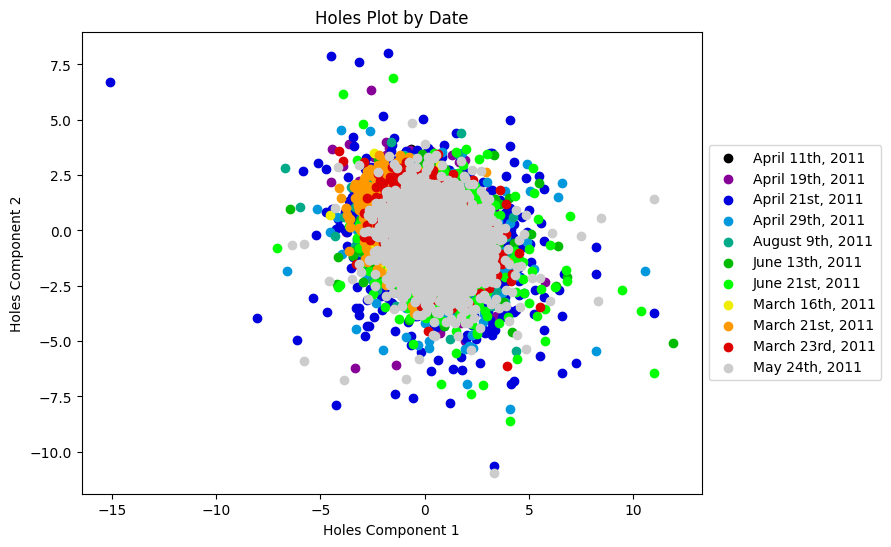

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Holes Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X_samp['Date'].unique():
  plt.scatter(X_samp[X_samp['Date']==i]['Projection 1.2'], X_samp[X_samp['Date']==i]['Projection 2.2'], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Holes Component 1')
plt.ylabel('Holes Component 2')
plt.show()

### Modeling

In [ ]:
random_column

'Cells_AreaShape_Zernike_8_6'

In [ ]:
# Get list of column names
columns = X.columns.tolist()
# Choose a random column
random_column = random.choice(columns)

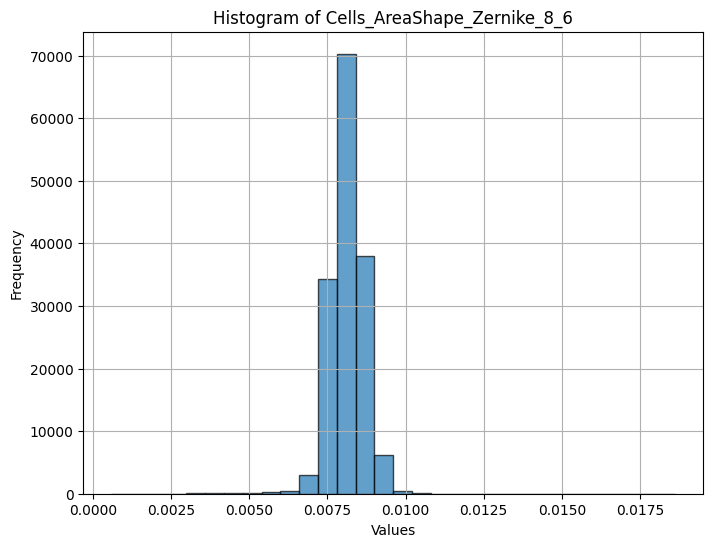

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(X[random_column], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title(f'Histogram of {random_column}')
plt.grid(True)
plt.show()

In [ ]:
ss = StandardScaler()
Xs = ss.fit_transform(X[X.columns[17:-9]])

In [ ]:
tsne = TSNE(perplexity = 10)
X_tsne_10 = tsne.fit_transform(Xs)
tsne = TSNE(perplexity = 30)
X_tsne_30 = tsne.fit_transform(Xs)
tsne = TSNE(perplexity = 50)
X_tsne_50 = tsne.fit_transform(Xs)

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50 = umap.fit_transform(Xs)

In [ ]:
umap = UMAP(n_components=2, n_neighbors = 10)
X_umap_10 = umap.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 10)
X_umap_30 = umap.fit_transform(Xs)

In [ ]:
X_train, X_test = train_test_split(Xs, test_size=0.2, random_state=42)

In [ ]:
class Autoencoder(Model):
  def __init__(self, latent_dim, shape):
    super(Autoencoder, self).__init__()
    self.latent_dim = latent_dim
    self.shape = shape
    self.encoder = tf.keras.Sequential([
      layers.Dense(100, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(latent_dim, activation='tanh'),
    ])
    self.decoder = tf.keras.Sequential([
      layers.Dense(100, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(50, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(tf.math.reduce_prod(shape).numpy(), activation='sigmoid'),
      layers.Reshape(shape)
    ])
  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded
shape = X_test.shape[1:]
latent_dim = 2
autoencoder = Autoencoder(latent_dim, shape)

In [ ]:
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

In [ ]:
autoencoder.fit(X_train, X_train,
                epochs=5,
                shuffle=True,
                validation_data=(X_test, X_test))

Epoch 1/5
3835/3835 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - loss: 0.8506 - val_loss: 0.7617
Epoch 2/5
3835/3835 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.7701 - val_loss: 0.7514
Epoch 3/5
3835/3835 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - loss: 0.7551 - val_loss: 0.7479
Epoch 4/5
3835/3835 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - loss: 0.7501 - val_loss: 0.7440
Epoch 5/5
3835/3835 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - loss: 0.7549 - val_loss: 0.7426


In [ ]:
encoded_imgs = autoencoder.encoder(X_test).numpy()

In [ ]:
df = X_tsne_10

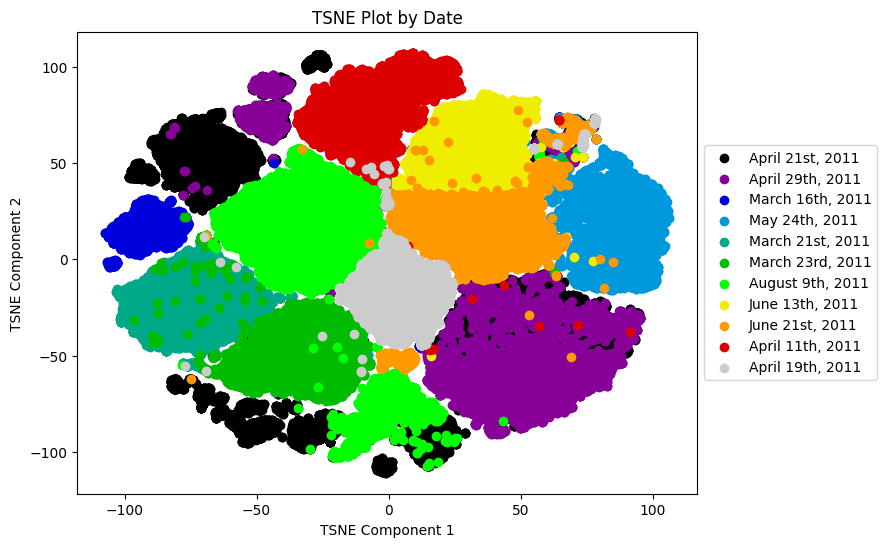

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_30

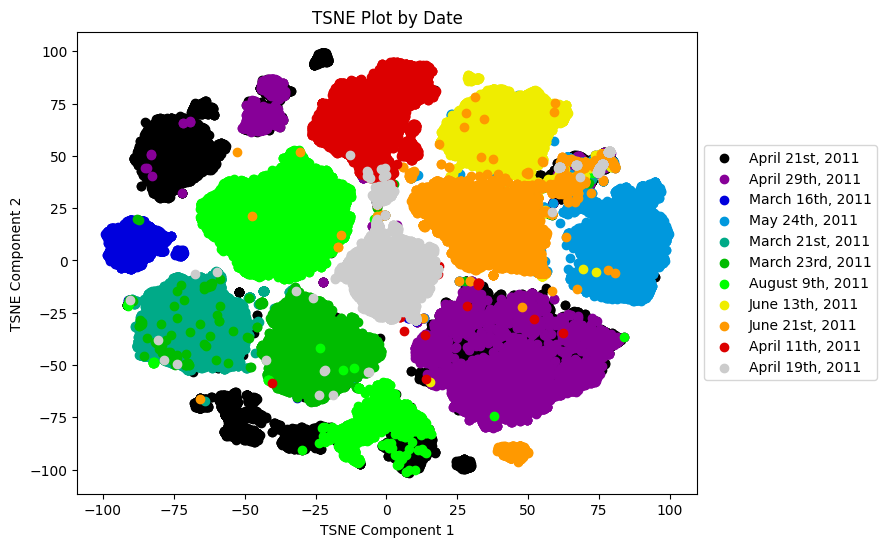

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_tsne_50

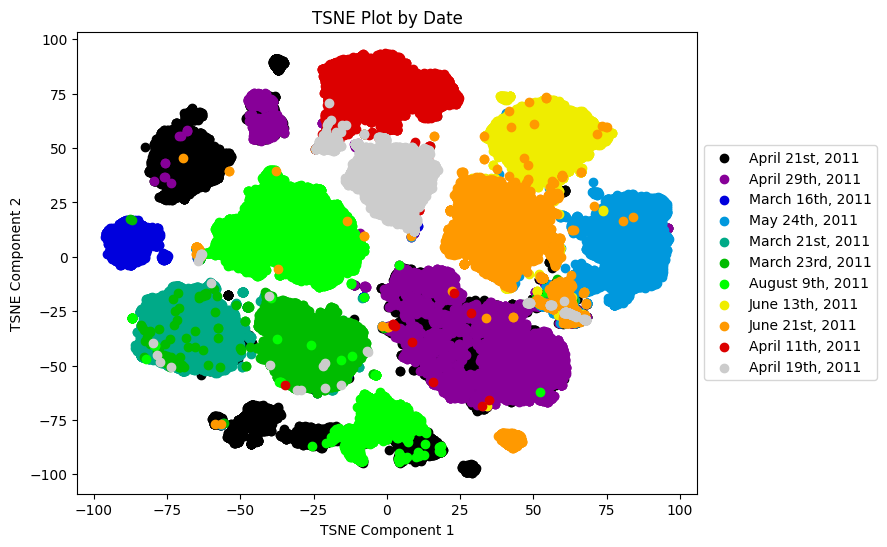

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df=X_pca

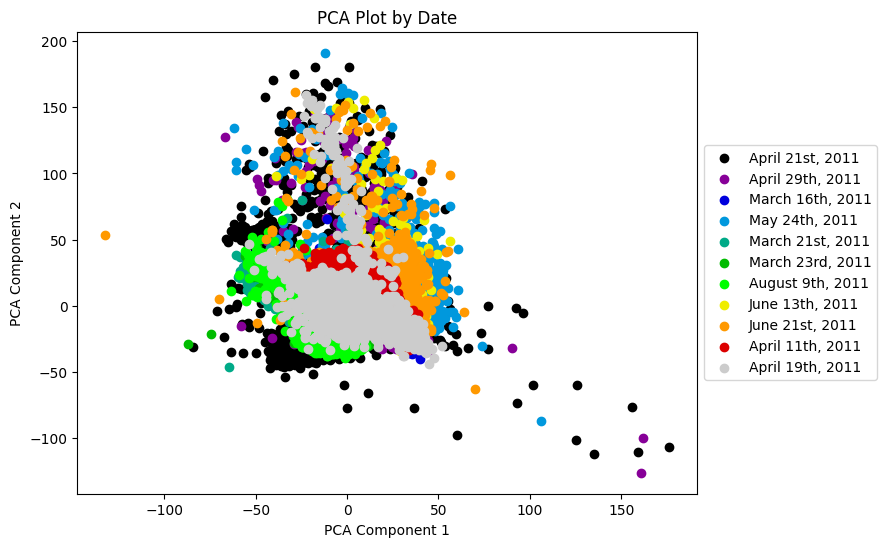

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [ ]:
df = X_umap_10

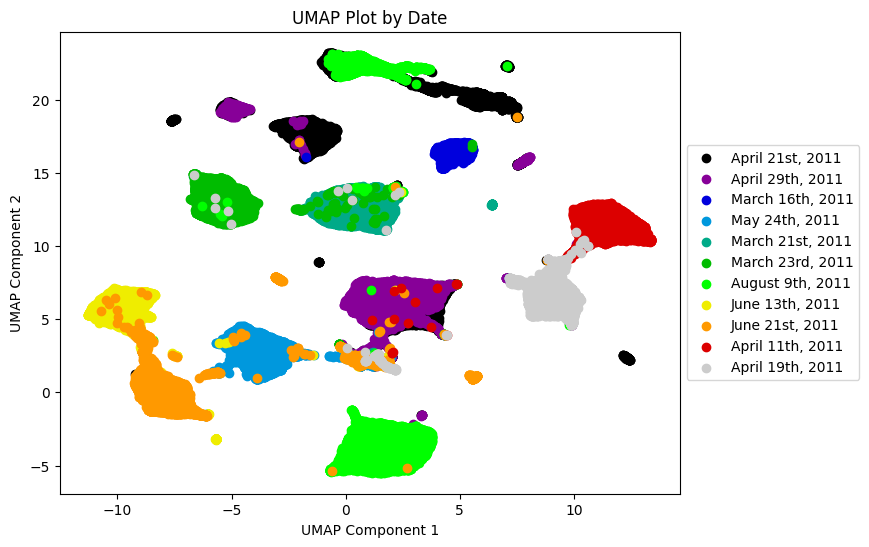

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_umap_30

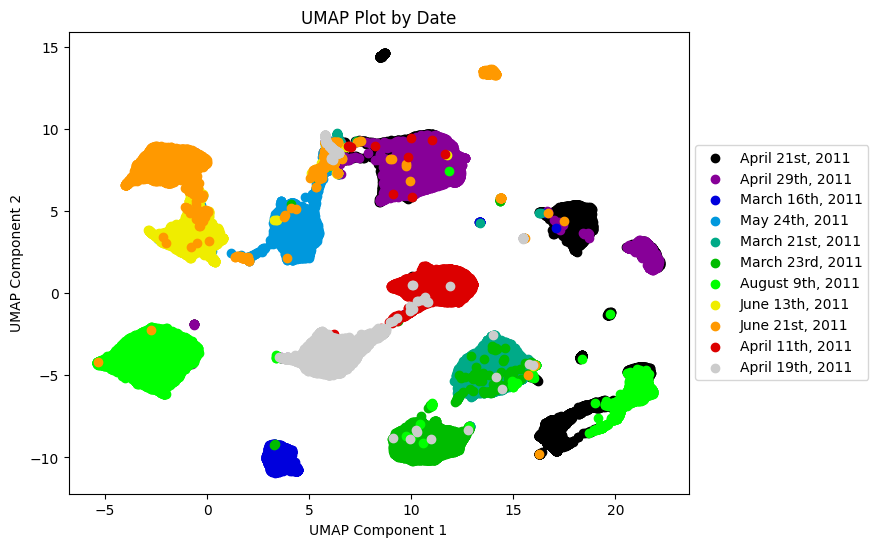

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df=X_umap_50

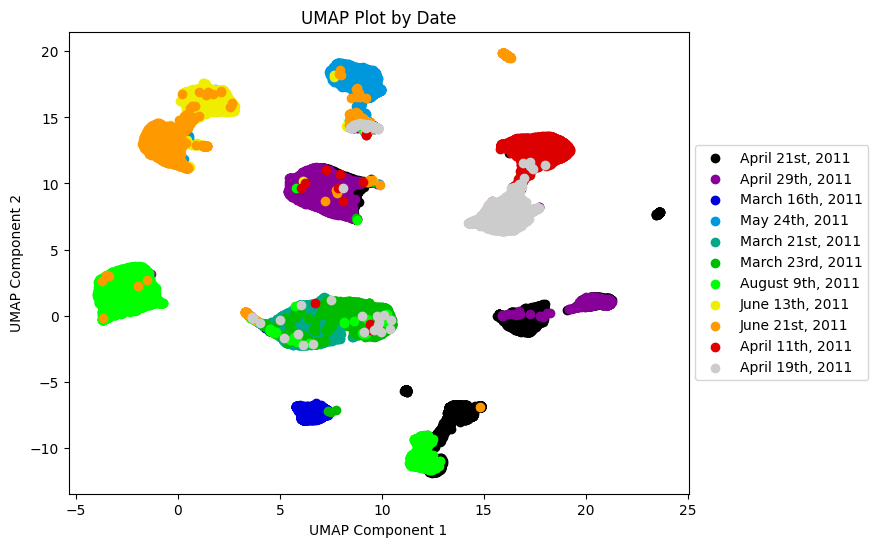

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = encoded_imgs

In [ ]:
x_df = pd.DataFrame(Xs)
x_df['cell_line'] = X['Date']
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

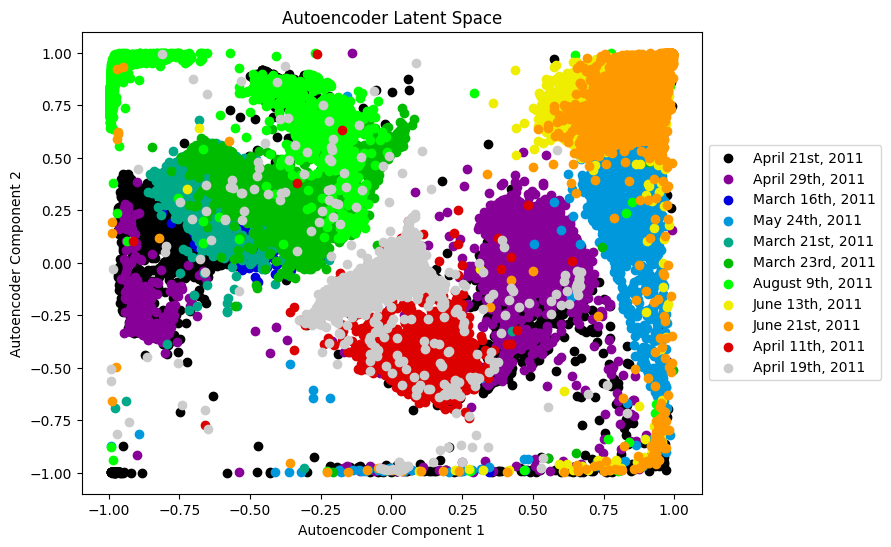

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('Autoencoder Latent Space')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[cell_line_test==i,0], df[cell_line_test==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('Autoencoder Component 1')
plt.ylabel('Autoencoder Component 2')
plt.show()

In [ ]:
X_train, X_test = train_test_split(X_tsne_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9831632819376079, test score = 0.9823000195579894


In [ ]:
X_train, X_test = train_test_split(X_tsne_30, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9823238908628614, test score = 0.9799856574744116


In [ ]:
X_train, X_test = train_test_split(X_tsne_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9816311894904978, test score = 0.9796270943347024


In [ ]:
X_train, X_test = train_test_split(X_pca, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.6313850767676109, test score = 0.5656170545667906


In [ ]:
X_train, X_test = train_test_split(X_umap_10, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9746145320598494, test score = 0.9702392594041332


In [ ]:
X_train, X_test = train_test_split(X_umap_30, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9740196238224077, test score = 0.969880696264424


In [ ]:
X_train, X_test = train_test_split(X_umap_50, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.9629119535808586, test score = 0.9586022556881153


In [ ]:
x_df = pd.DataFrame(X_samp)
x_df['cell_line'] = X_samp['Date']
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
cell_line_train = X_train['cell_line']
cell_line_test = X_test['cell_line']

In [ ]:
X_train, X_test = train_test_split(holes_df, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.3156886715566422, test score = 0.16753585397653195


In [ ]:
cell_line_train, cell_line_test = train_test_split(cell_line_test, test_size=0.2, random_state=42)

In [ ]:
X_train, X_test = train_test_split(encoded_imgs, test_size=0.2, random_state=42)
k=10
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, cell_line_train)
training_score = clf.score(X_train,cell_line_train)
test_score = clf.score(X_test, cell_line_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 10, training score = 0.8936109526525956, test score = 0.8751629726205997


### Plate Normalization

In [ ]:
X = X.dropna(subset=['Metadata_moa'])
X

,Metadata_Plate,Metadata_Well,Metadata_Assay_Plate_Barcode,Metadata_Plate_Map_Name,Metadata_well_position,Metadata_ASSAY_WELL_ROLE,Metadata_broad_sample,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,...,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,Metadata_pert_iname,Metadata_pert_iname2,Metadata_moa,Metadata_target,Metadata_mmoles_per_liter2,Metadata_Sample_Dose,pert_type,control_type
0,24277,a01,24277,H-BIOA-004-3,a01,treated,BRD-K18250272-003-03-7,3.022516,DMSO,BRD-K18250272,...,2.376336,2.402145,propoxycaine,propoxycaine,local anesthetic,NaN,6.05,BRD-K18250272-003-03-7_6.05,trt,NaN
1,24277,a02,24277,H-BIOA-004-3,a02,treated,BRD-K18316707-001-01-9,5.000000,DMSO,BRD-K18316707,...,2.428562,2.458853,O-1918,BRD-K18316707,cannabinoid receptor antagonist,NaN,10.00,BRD-K18316707-001-01-9_10.0,trt,NaN
3,24277,a04,24277,H-BIOA-004-3,a04,treated,BRD-K18550767-001-02-8,5.000000,DMSO,BRD-K18550767,...,2.529105,2.598130,bergenin,bergenin,interleukin inhibitor,"IL1B, TNF",10.00,BRD-K18550767-001-02-8_10.0,trt,NaN
4,24277,a05,24277,H-BIOA-004-3,a05,treated,BRD-K18574842-323-03-3,2.195487,DMSO,BRD-K18574842,...,2.590156,2.649836,nafcillin,nafcillin,bacterial cell wall synthesis inhibitor,"CYP1A2, CYP3A4, SLC22A6",4.39,BRD-K18574842-323-03-3_4.39,trt,NaN
5,24277,a06,24277,H-BIOA-004-3,a06,treated,BRD-K18619710-001-03-7,2.560734,DMSO,BRD-K18619710,...,3.353058,3.596338,digoxigenin,digoxigenin,steroid,NaN,5.12,BRD-K18619710-001-03-7_5.12,trt,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124461,26247,p18,26247,H-BIOA-007-3,p18,treated,BRD-K98143437-001-01-7,5.000000,DMSO,BRD-K98143437,...,2.013557,2.043480,SB-239063,BRD-K98143437,p38 MAPK inhibitor|interleukin inhibitor|tumor...,"MAPK11, MAPK14, PTGS2, TNF",10.00,BRD-K98143437-001-01-7_10.0,trt,NaN
124463,26247,p20,26247,H-BIOA-007-3,p20,treated,BRD-K98157055-001-04-2,5.000000,DMSO,BRD-K98157055,...,2.289077,2.367173,SIB-1757,BRD-K98157055,glutamate receptor antagonist,GRM5,10.00,BRD-K98157055-001-04-2_10.0,trt,NaN
124464,26247,p21,26247,H-BIOA-007-3,p21,treated,BRD-K98174813-001-05-7,5.897438,DMSO,BRD-K98174813,...,2.323810,2.367912,chlorzoxazone,chlorzoxazone,bacterial 30S ribosomal subunit inhibitor,"KCNMA1, KCNN4",11.79,BRD-K98174813-001-05-7_11.79,trt,NaN
124466,26247,p23,26247,H-BIOA-007-3,p23,treated,BRD-K98297262-001-01-1,5.000000,DMSO,BRD-K98297262,...,2.004905,2.065283,NaN,N-ethylmaleimide,"1,3-beta-glucan synthase inhibitor",CLC,10.00,BRD-K98297262-001-01-1_10.0,trt,NaN


In [ ]:
df_list = []
for i in X['Metadata_Plate'].unique():
  plate_df = X[X['Metadata_Plate']==i]
  ss = StandardScaler()
  Xs = ss.fit_transform(plate_df[plate_df.columns[17:-9]])
  df_list.append(pd.DataFrame(Xs))

In [ ]:
Xs = pd.concat(df_list)

In [ ]:
tsne = TSNE()
X_tsne = tsne.fit_transform(Xs)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50 = umap.fit_transform(Xs)

In [ ]:
df = X_tsne

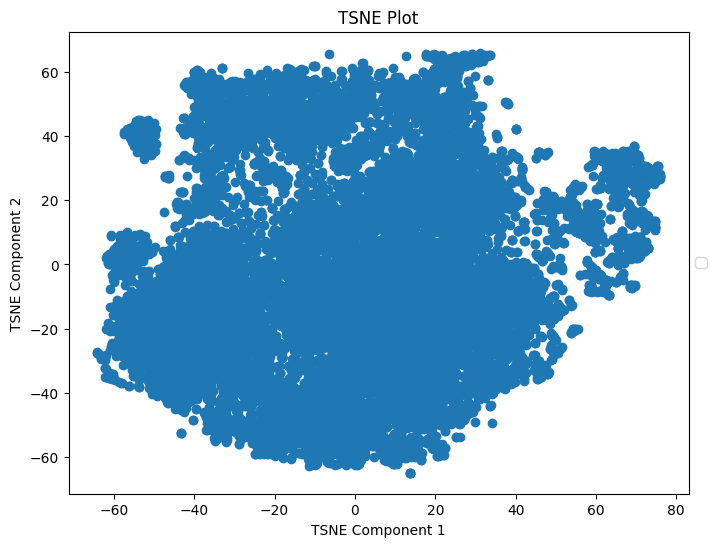

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(X_tsne[:,0], X_tsne[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
df = X_umap_50

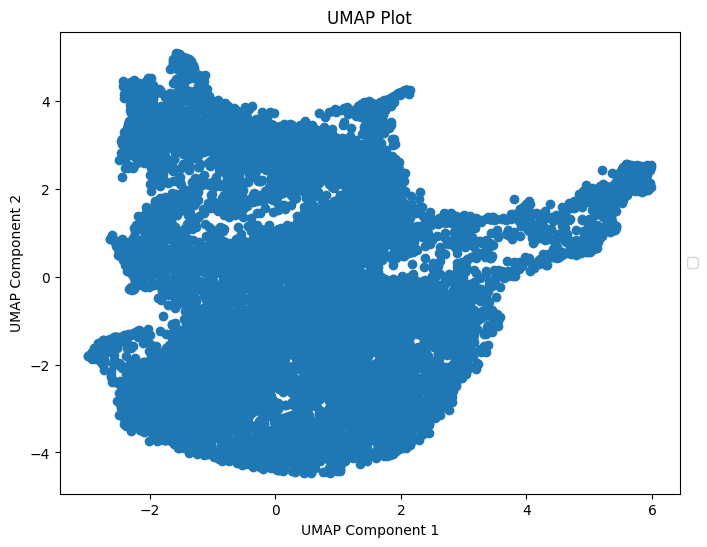

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot')
plt.scatter(X_umap_50[:,0], X_umap_50[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_pca

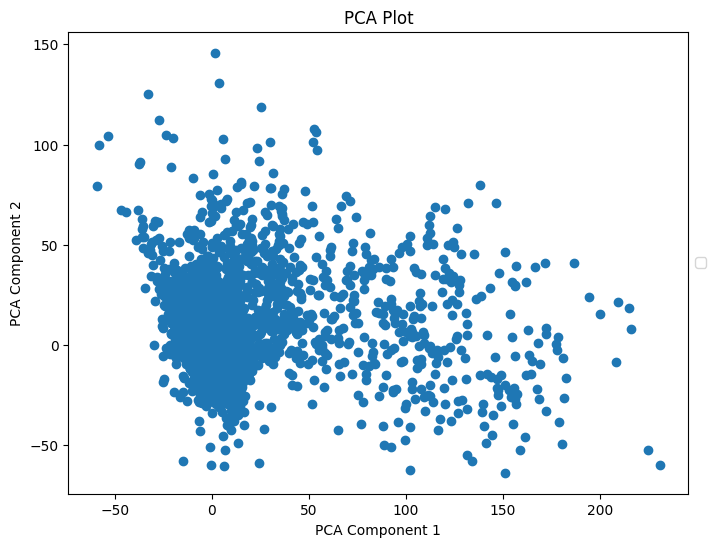

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot')
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [ ]:
df = X_tsne

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=3
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 3, training score = 0.3909658916316706, test score = 0.07128226136829169


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-40-fa63c7cb04f7>:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


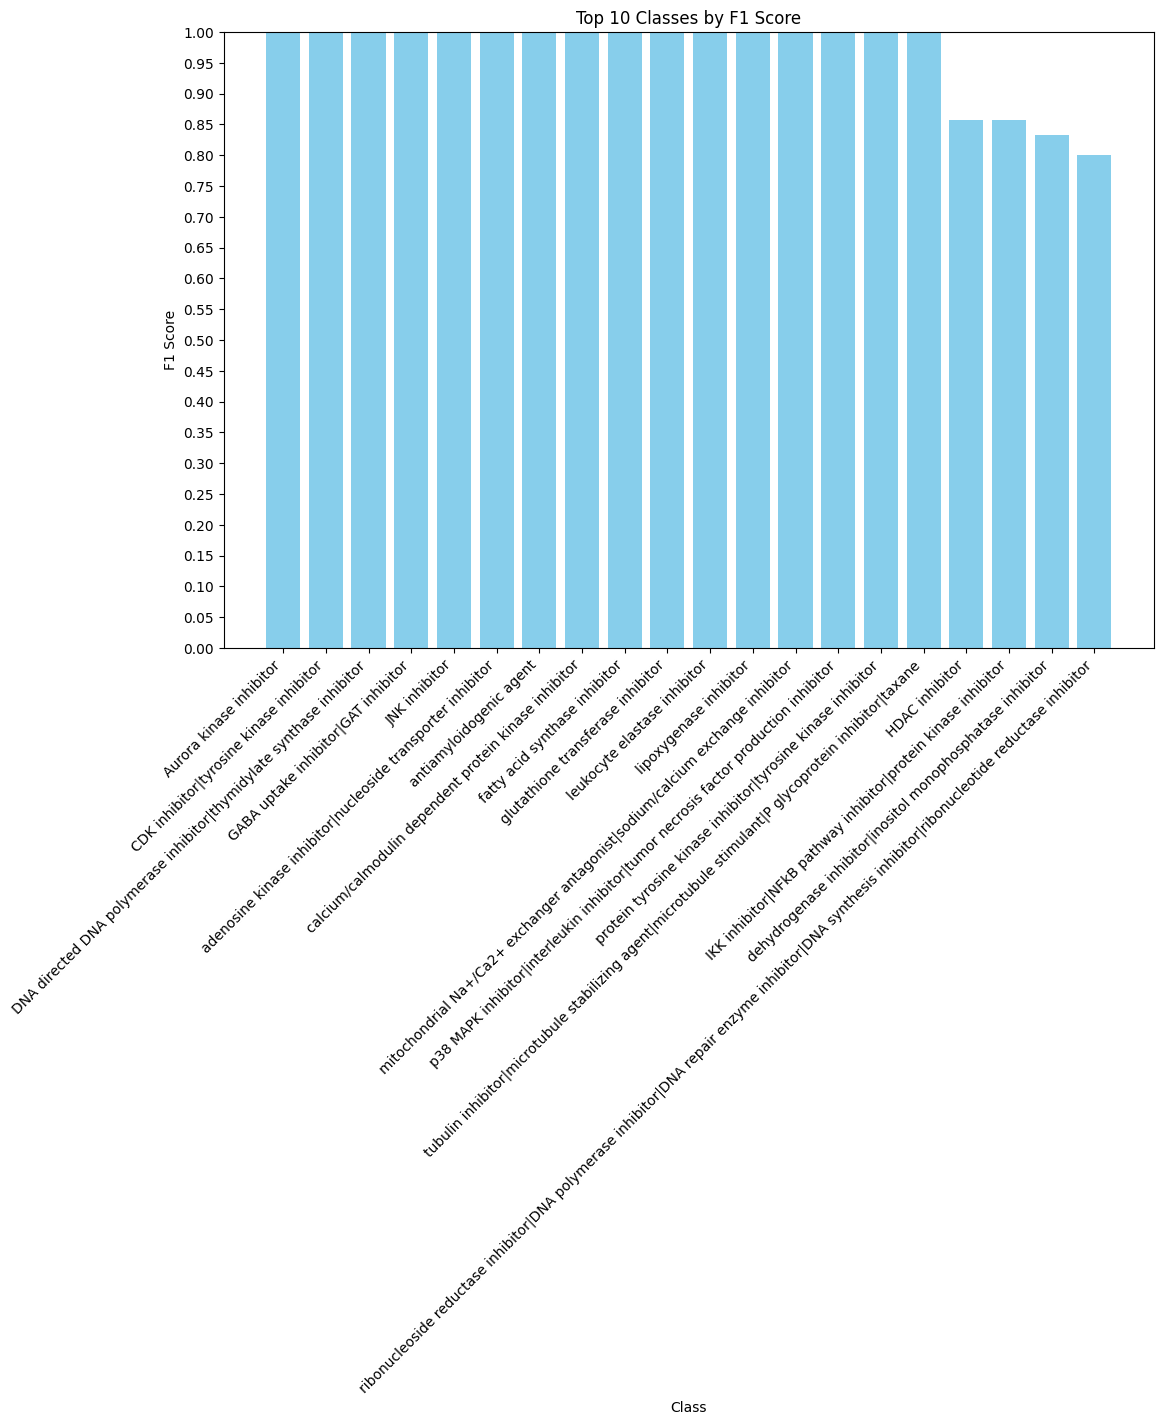

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:20]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
df = X_umap_50

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=3
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 3, training score = 0.35214585680630955, test score = 0.020483408439164276


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))
<ipython-input-51-fa63c7cb04f7>:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


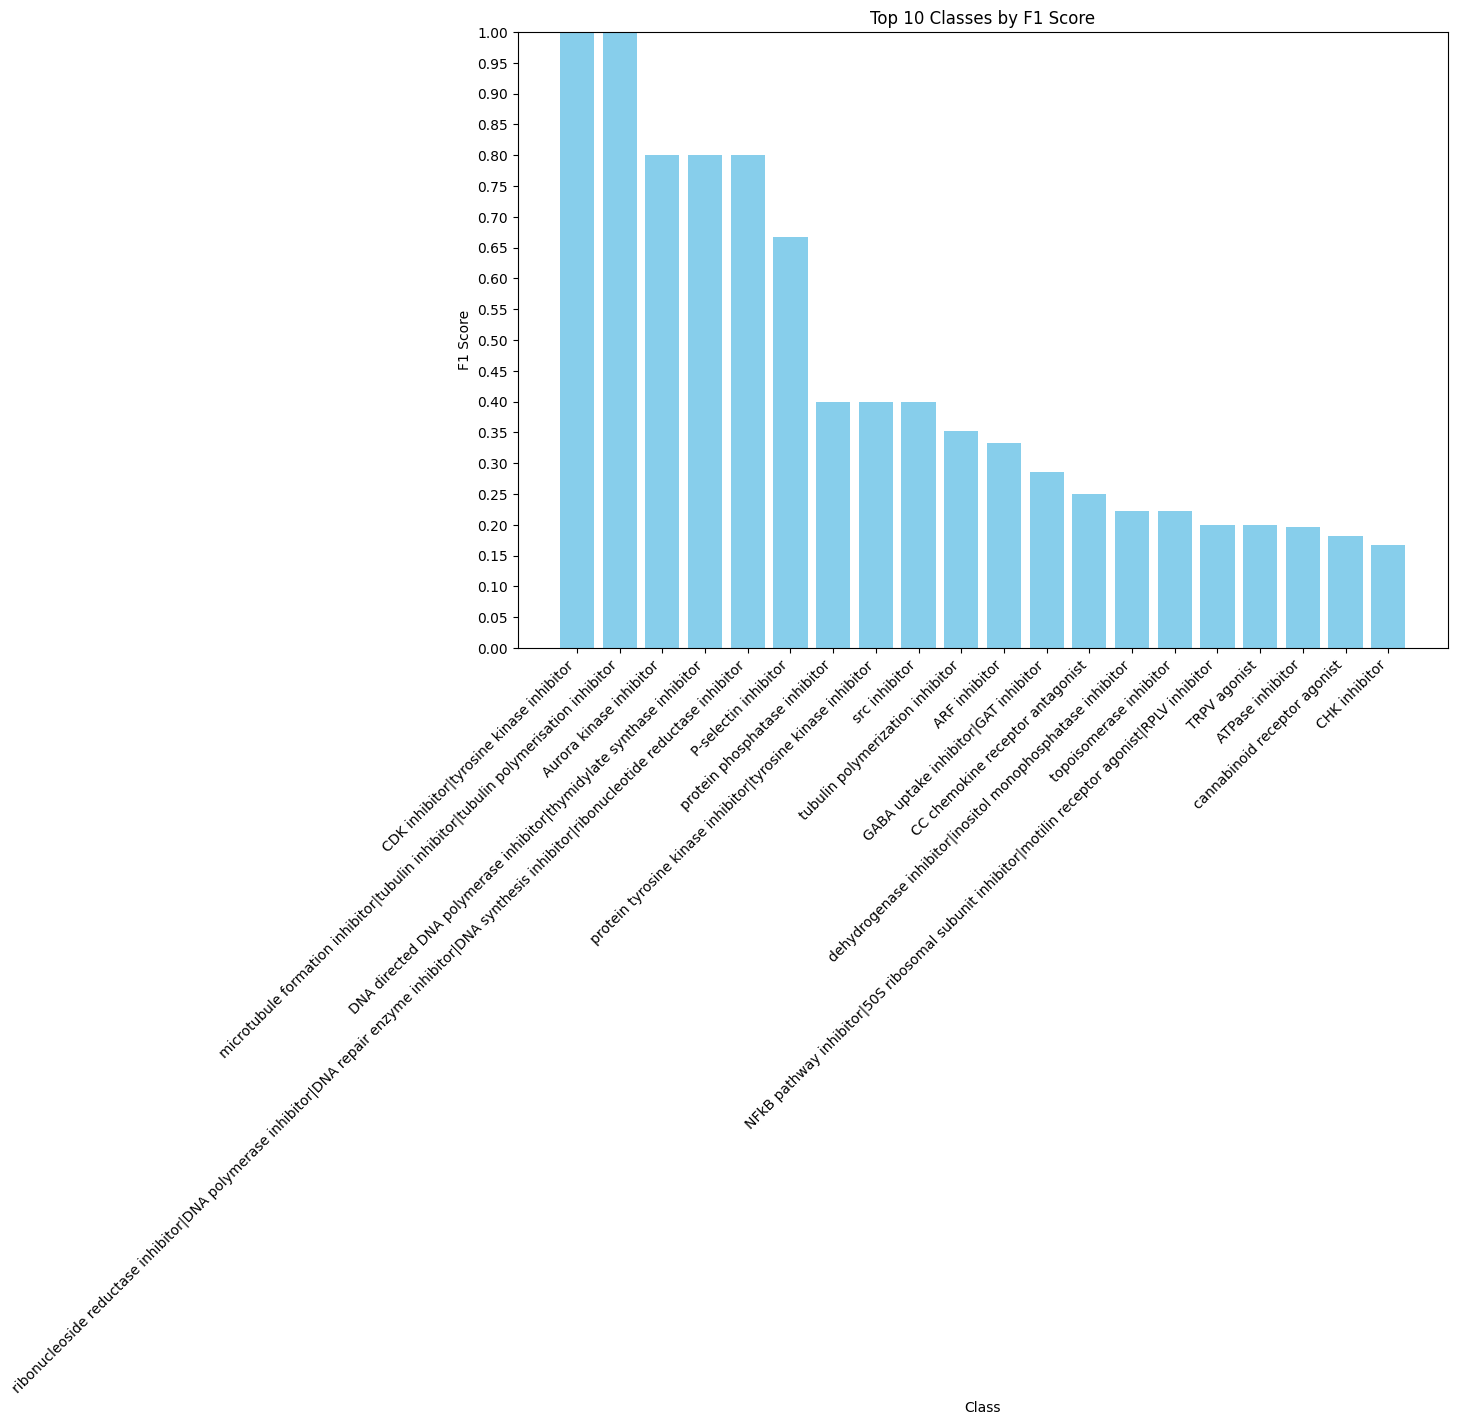

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:20]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
df = X_pca

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=3
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 3, training score = 0.34825361057052134, test score = 0.013109381401065138


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


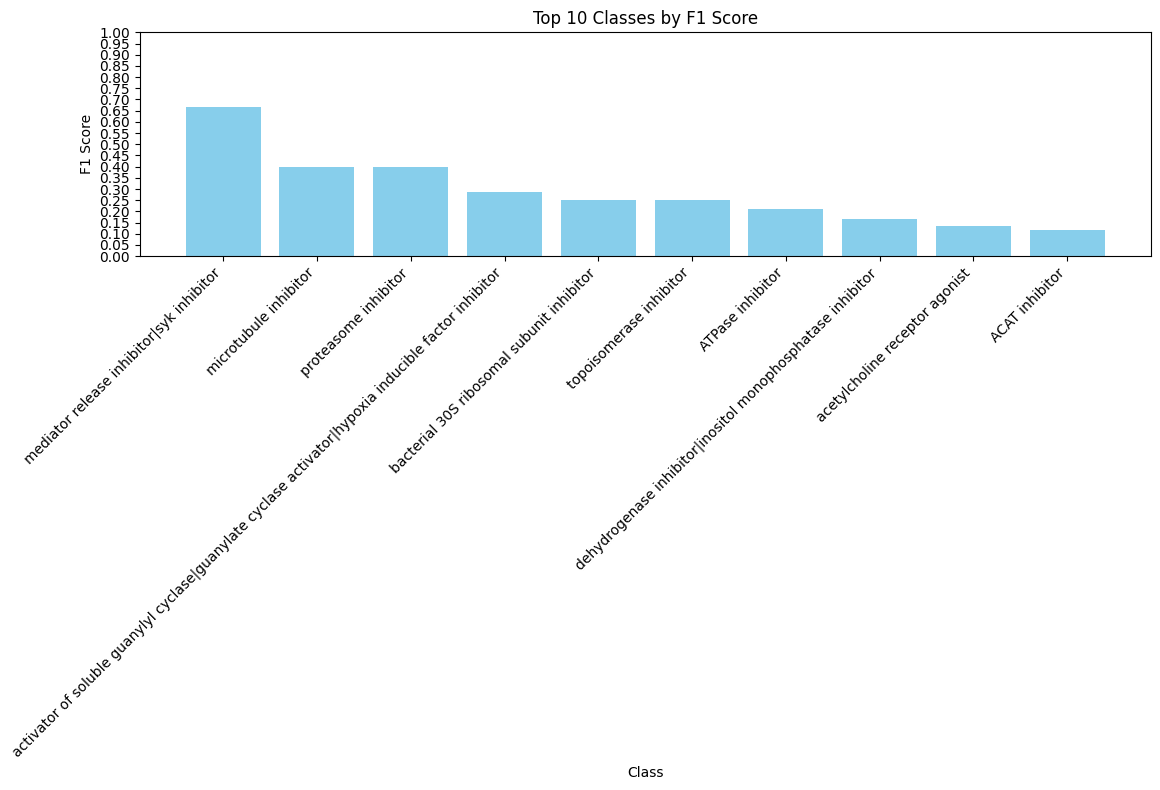

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.05))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

### Drop NA for the MoA column

In [ ]:
X = X.dropna(subset=['Metadata_moa'])
X

,Metadata_Plate,Metadata_Well,Metadata_Assay_Plate_Barcode,Metadata_Plate_Map_Name,Metadata_well_position,Metadata_ASSAY_WELL_ROLE,Metadata_broad_sample,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,...,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,Metadata_pert_iname,Metadata_pert_iname2,Metadata_moa,Metadata_target,Metadata_mmoles_per_liter2,Metadata_Sample_Dose,pert_type,control_type
0,24277,a01,24277,H-BIOA-004-3,a01,treated,BRD-K18250272-003-03-7,3.022516,DMSO,BRD-K18250272,...,2.376336,2.402145,propoxycaine,propoxycaine,local anesthetic,NaN,6.05,BRD-K18250272-003-03-7_6.05,trt,NaN
1,24277,a02,24277,H-BIOA-004-3,a02,treated,BRD-K18316707-001-01-9,5.000000,DMSO,BRD-K18316707,...,2.428562,2.458853,O-1918,BRD-K18316707,cannabinoid receptor antagonist,NaN,10.00,BRD-K18316707-001-01-9_10.0,trt,NaN
3,24277,a04,24277,H-BIOA-004-3,a04,treated,BRD-K18550767-001-02-8,5.000000,DMSO,BRD-K18550767,...,2.529105,2.598130,bergenin,bergenin,interleukin inhibitor,"IL1B, TNF",10.00,BRD-K18550767-001-02-8_10.0,trt,NaN
4,24277,a05,24277,H-BIOA-004-3,a05,treated,BRD-K18574842-323-03-3,2.195487,DMSO,BRD-K18574842,...,2.590156,2.649836,nafcillin,nafcillin,bacterial cell wall synthesis inhibitor,"CYP1A2, CYP3A4, SLC22A6",4.39,BRD-K18574842-323-03-3_4.39,trt,NaN
5,24277,a06,24277,H-BIOA-004-3,a06,treated,BRD-K18619710-001-03-7,2.560734,DMSO,BRD-K18619710,...,3.353058,3.596338,digoxigenin,digoxigenin,steroid,NaN,5.12,BRD-K18619710-001-03-7_5.12,trt,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124461,26247,p18,26247,H-BIOA-007-3,p18,treated,BRD-K98143437-001-01-7,5.000000,DMSO,BRD-K98143437,...,2.013557,2.043480,SB-239063,BRD-K98143437,p38 MAPK inhibitor|interleukin inhibitor|tumor...,"MAPK11, MAPK14, PTGS2, TNF",10.00,BRD-K98143437-001-01-7_10.0,trt,NaN
124463,26247,p20,26247,H-BIOA-007-3,p20,treated,BRD-K98157055-001-04-2,5.000000,DMSO,BRD-K98157055,...,2.289077,2.367173,SIB-1757,BRD-K98157055,glutamate receptor antagonist,GRM5,10.00,BRD-K98157055-001-04-2_10.0,trt,NaN
124464,26247,p21,26247,H-BIOA-007-3,p21,treated,BRD-K98174813-001-05-7,5.897438,DMSO,BRD-K98174813,...,2.323810,2.367912,chlorzoxazone,chlorzoxazone,bacterial 30S ribosomal subunit inhibitor,"KCNMA1, KCNN4",11.79,BRD-K98174813-001-05-7_11.79,trt,NaN
124466,26247,p23,26247,H-BIOA-007-3,p23,treated,BRD-K98297262-001-01-1,5.000000,DMSO,BRD-K98297262,...,2.004905,2.065283,NaN,N-ethylmaleimide,"1,3-beta-glucan synthase inhibitor",CLC,10.00,BRD-K98297262-001-01-1_10.0,trt,NaN


In [ ]:
ss = StandardScaler()
Xs = ss.fit_transform(X[X.columns[17:-9]])

In [ ]:
tsne = TSNE()
X_tsne = tsne.fit_transform(Xs)

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50 = umap.fit_transform(Xs)

In [ ]:
df = X_tsne

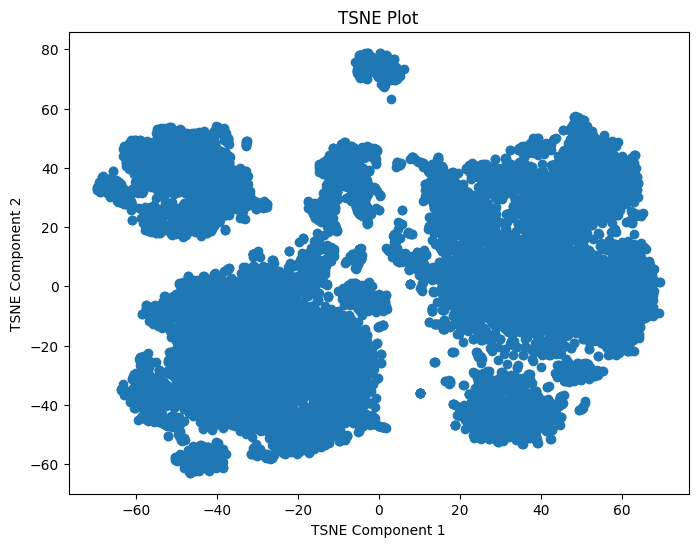

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot')
plt.scatter(df[:,0],df[:,1])
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

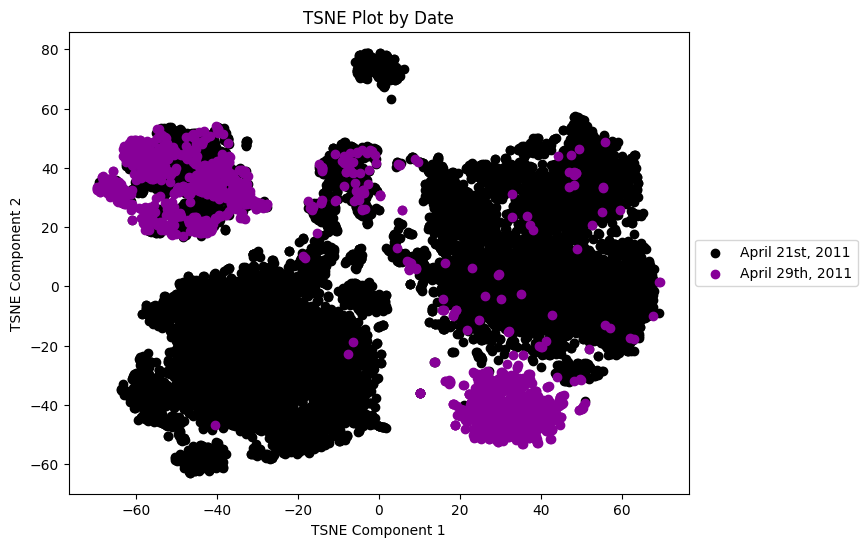

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

In [ ]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train_test_split(X['Metadata_moa'], test_size=0.2, random_state=42)
k=3
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, y_train)
training_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 5, training score = 0.2618047731230155, test score = 0.04506349856616141


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1760: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


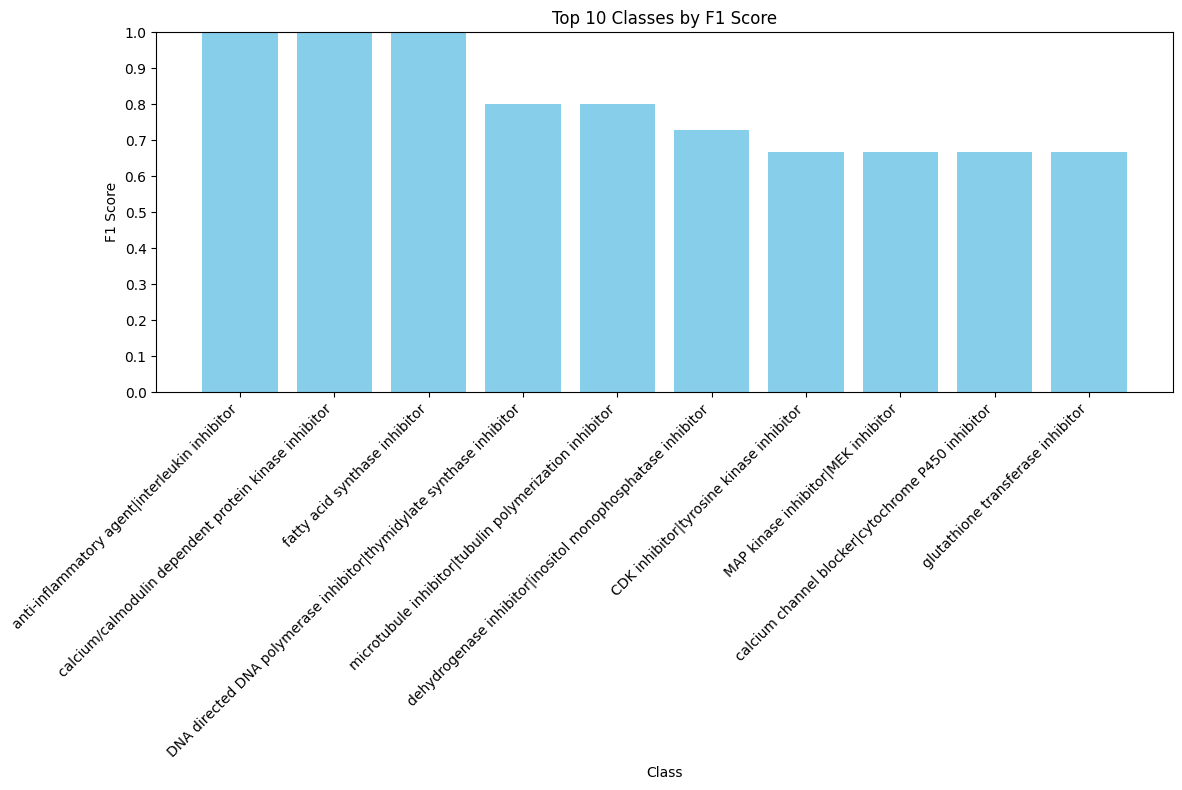

In [ ]:
y_pred = clf.predict(X_test)
# Calculate F1 scores for each class
f1_scores = f1_score(y_test, y_pred, average=None, labels = np.unique(X['Metadata_moa']))

# Create a dictionary of class names and their F1 scores
f1_scores_dict = {np.unique(X['Metadata_moa'])[i]: f1_scores[i] for i in range(len(np.unique(X['Metadata_moa'])))}

# Sort the classes by their F1 score
sorted_f1_scores = sorted(f1_scores_dict.items(), key=lambda item: item[1], reverse=True)

# Take the top 10 F1 scores (or fewer if there are not enough classes)
top_10_f1_scores = sorted_f1_scores[:10]

# Extract class labels and scores
classes = [item[0] for item in top_10_f1_scores]
scores = [item[1] for item in top_10_f1_scores]

# Plot the bar graph
plt.figure(figsize=(12, 8))
plt.bar(classes, scores, color='skyblue')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.title('Top 10 Classes by F1 Score')
plt.xticks(classes)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(classes, rotation=45, ha='right')
plt.ylim(0, 1)  # F1 scores range from 0 to 1
plt.tight_layout()
plt.show()

In [ ]:
df = X_umap_50

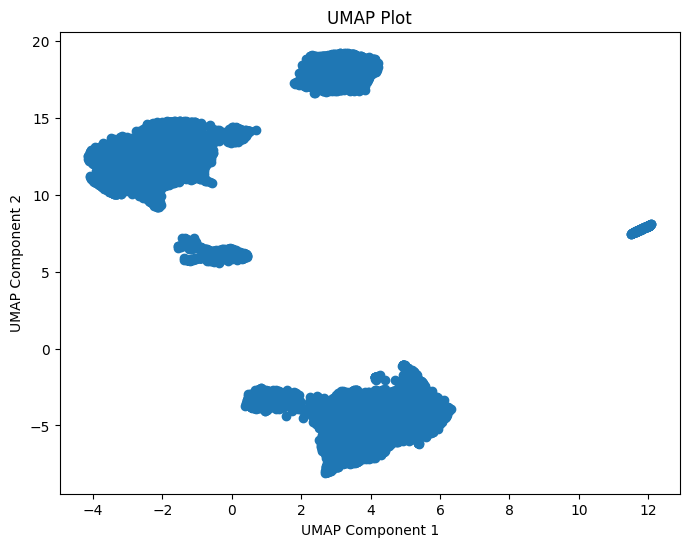

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('UMAP Plot')
plt.scatter(df[:,0],df[:,1])
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.show()

In [ ]:
df = X_pca

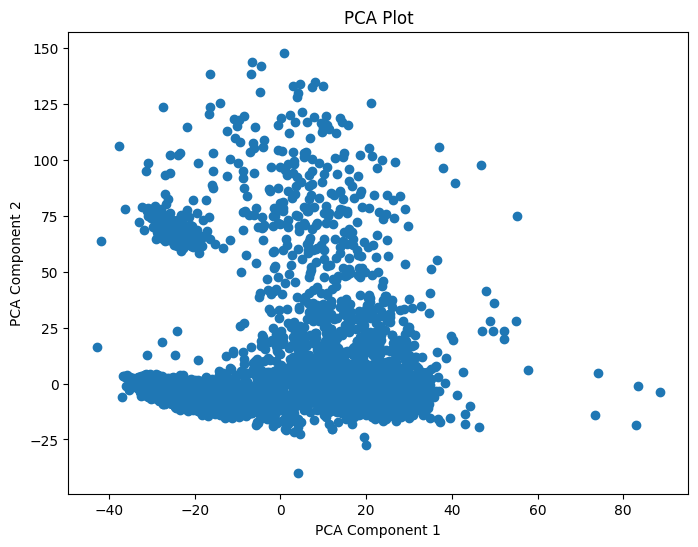

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot')
plt.scatter(df[:,0],df[:,1])
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))
plt.title('PCA Plot by Date')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X['Date'].unique():
  plt.scatter(df[X['Date']==i,0], df[X['Date']==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

### Looking in the August 9th cluster

In [ ]:
X_89 = X[X['Date']=='August 9th, 2011']
X_89

,Metadata_Plate,Metadata_Well,Metadata_Assay_Plate_Barcode,Metadata_Plate_Map_Name,Metadata_well_position,Metadata_ASSAY_WELL_ROLE,Metadata_broad_sample,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,...,Nuclei_Texture_Variance_RNA_5_0,Metadata_pert_iname,Metadata_pert_iname2,Metadata_moa,Metadata_target,Metadata_mmoles_per_liter2,Metadata_Sample_Dose,pert_type,control_type,Date
39107,24726,a01,24726,H-CBLD-001-4,a01,treated,BRD-K25430810-001-02-1,5.016283,DMSO,BRD-K25430810,...,2.424007,NaN,NaN,NaN,NaN,10.03,BRD-K25430810-001-02-1_10.03,trt,NaN,"August 9th, 2011"
39108,24726,a02,24726,H-CBLD-001-4,a02,treated,BRD-K54071713-001-01-7,5.123618,DMSO,BRD-K54071713,...,2.507605,NaN,NaN,NaN,NaN,10.25,BRD-K54071713-001-01-7_10.25,trt,NaN,"August 9th, 2011"
39109,24726,a03,24726,H-CBLD-001-4,a03,treated,BRD-K44541805-001-02-9,5.020993,DMSO,BRD-K44541805,...,2.669448,NaN,NaN,NaN,NaN,10.04,BRD-K44541805-001-02-9_10.04,trt,NaN,"August 9th, 2011"
39110,24726,a04,24726,H-CBLD-001-4,a04,treated,BRD-K48211485-001-01-4,4.919639,DMSO,BRD-K48211485,...,2.579181,NaN,NaN,NaN,NaN,9.84,BRD-K48211485-001-01-4_9.84,trt,NaN,"August 9th, 2011"
39111,24726,a05,24726,H-CBLD-001-4,a05,treated,BRD-K93061442-001-01-9,4.890421,DMSO,BRD-K93061442,...,2.594025,NaN,NaN,NaN,NaN,9.78,BRD-K93061442-001-01-9_9.78,trt,NaN,"August 9th, 2011"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153381,26795,p20,26795,H-CBLD-004-4,p20,treated,BRD-K17405724-001-01-0,4.916061,DMSO,BRD-K17405724,...,2.259248,NaN,NaN,NaN,NaN,9.83,BRD-K17405724-001-01-0_9.83,trt,NaN,"August 9th, 2011"
153382,26795,p21,26795,H-CBLD-004-4,p21,treated,BRD-K90170141-001-01-5,4.859274,DMSO,BRD-K90170141,...,2.237415,NaN,NaN,NaN,NaN,9.72,BRD-K90170141-001-01-5_9.72,trt,NaN,"August 9th, 2011"
153383,26795,p22,26795,H-CBLD-004-4,p22,treated,BRD-K45307499-001-01-7,5.109445,DMSO,BRD-K45307499,...,2.240176,NaN,NaN,NaN,NaN,10.22,BRD-K45307499-001-01-7_10.22,trt,NaN,"August 9th, 2011"
153384,26795,p23,26795,H-CBLD-004-4,p23,treated,BRD-K84521261-001-01-1,4.958284,DMSO,BRD-K84521261,...,2.300320,NaN,NaN,NaN,NaN,9.92,BRD-K84521261-001-01-1_9.92,trt,NaN,"August 9th, 2011"


In [ ]:
ss = StandardScaler()
Xs = ss.fit_transform(X[X.columns[17:-9]])

In [ ]:
tsne = TSNE()
X_tsne_89 = tsne.fit_transform(Xs)

In [ ]:
pca = PCA(n_components=2)
X_pca_89 = pca.fit_transform(Xs)
umap = UMAP(n_components=2, n_neighbors = 50)
X_umap_50_89 = umap.fit_transform(Xs)

In [ ]:
X_tsne = pd.read_csv('/content/drive/MyDrive/Honors/X_tsne_89.csv')

In [ ]:
X_tsne = X_tsne.drop('Unnamed: 0', axis = 1).values

In [ ]:
df = X_tsne

In [ ]:
sum(X.iloc[:,-7].value_counts())

12204

In [ ]:
X.dropna(subset=['Metadata_moa'], inplace=True)

In [ ]:
X

,Metadata_Plate,Metadata_Well,Metadata_Assay_Plate_Barcode,Metadata_Plate_Map_Name,Metadata_well_position,Metadata_ASSAY_WELL_ROLE,Metadata_broad_sample,Metadata_mmoles_per_liter,Metadata_solvent,Metadata_pert_id,...,Nuclei_Texture_Variance_RNA_5_0,Metadata_pert_iname,Metadata_pert_iname2,Metadata_moa,Metadata_target,Metadata_mmoles_per_liter2,Metadata_Sample_Dose,pert_type,control_type,Date
0,24277,a01,24277,H-BIOA-004-3,a01,treated,BRD-K18250272-003-03-7,3.022516,DMSO,BRD-K18250272,...,2.402145,propoxycaine,propoxycaine,local anesthetic,NaN,6.05,BRD-K18250272-003-03-7_6.05,trt,NaN,"April 21st, 2011"
1,24277,a02,24277,H-BIOA-004-3,a02,treated,BRD-K18316707-001-01-9,5.000000,DMSO,BRD-K18316707,...,2.458853,O-1918,BRD-K18316707,cannabinoid receptor antagonist,NaN,10.00,BRD-K18316707-001-01-9_10.0,trt,NaN,"April 21st, 2011"
3,24277,a04,24277,H-BIOA-004-3,a04,treated,BRD-K18550767-001-02-8,5.000000,DMSO,BRD-K18550767,...,2.598130,bergenin,bergenin,interleukin inhibitor,"IL1B, TNF",10.00,BRD-K18550767-001-02-8_10.0,trt,NaN,"April 21st, 2011"
4,24277,a05,24277,H-BIOA-004-3,a05,treated,BRD-K18574842-323-03-3,2.195487,DMSO,BRD-K18574842,...,2.649836,nafcillin,nafcillin,bacterial cell wall synthesis inhibitor,"CYP1A2, CYP3A4, SLC22A6",4.39,BRD-K18574842-323-03-3_4.39,trt,NaN,"April 21st, 2011"
5,24277,a06,24277,H-BIOA-004-3,a06,treated,BRD-K18619710-001-03-7,2.560734,DMSO,BRD-K18619710,...,3.596338,digoxigenin,digoxigenin,steroid,NaN,5.12,BRD-K18619710-001-03-7_5.12,trt,NaN,"April 21st, 2011"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124461,26247,p18,26247,H-BIOA-007-3,p18,treated,BRD-K98143437-001-01-7,5.000000,DMSO,BRD-K98143437,...,2.043480,SB-239063,BRD-K98143437,p38 MAPK inhibitor|interleukin inhibitor|tumor...,"MAPK11, MAPK14, PTGS2, TNF",10.00,BRD-K98143437-001-01-7_10.0,trt,NaN,"April 21st, 2011"
124463,26247,p20,26247,H-BIOA-007-3,p20,treated,BRD-K98157055-001-04-2,5.000000,DMSO,BRD-K98157055,...,2.367173,SIB-1757,BRD-K98157055,glutamate receptor antagonist,GRM5,10.00,BRD-K98157055-001-04-2_10.0,trt,NaN,"April 21st, 2011"
124464,26247,p21,26247,H-BIOA-007-3,p21,treated,BRD-K98174813-001-05-7,5.897438,DMSO,BRD-K98174813,...,2.367912,chlorzoxazone,chlorzoxazone,bacterial 30S ribosomal subunit inhibitor,"KCNMA1, KCNN4",11.79,BRD-K98174813-001-05-7_11.79,trt,NaN,"April 21st, 2011"
124466,26247,p23,26247,H-BIOA-007-3,p23,treated,BRD-K98297262-001-01-1,5.000000,DMSO,BRD-K98297262,...,2.065283,NaN,N-ethylmaleimide,"1,3-beta-glucan synthase inhibitor",CLC,10.00,BRD-K98297262-001-01-1_10.0,trt,NaN,"April 21st, 2011"


In [ ]:
X.iloc[:,-9]

,Metadata_pert_iname
0,propoxycaine
1,O-1918
2,NaN
3,bergenin
4,nafcillin
...,...
153381,NaN
153382,NaN
153383,NaN
153384,NaN


In [ ]:
X[['Metadata_moa','Metadata_pert_iname']]

,Metadata_moa,Metadata_pert_iname
0,local anesthetic,propoxycaine
1,cannabinoid receptor antagonist,O-1918
2,NaN,NaN
3,interleukin inhibitor,bergenin
4,bacterial cell wall synthesis inhibitor,nafcillin
...,...,...
153381,NaN,NaN
153382,NaN,NaN
153383,NaN,NaN
153384,NaN,NaN


In [ ]:
plt.figure(figsize=(8, 6))
plt.title('TSNE Plot by MoA')
colormap = plt.cm.nipy_spectral
colors = colormap(np.linspace(0, 1, 11))
plt.gca().set_prop_cycle('color',colors)
for i in X[X.columns[-6]].unique():
  plt.scatter(df[X[X.columns[-6]]==i,0], df[X[X.columns[-6]]==i,1], label = i)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('TSNE Component 1')
plt.ylabel('TSNE Component 2')
plt.show()

KeyboardInterrupt: 

### Old Code

In [ ]:
X.groupby('Date', group_keys=False).apply(lambda x: x.sample(frac=0.2)).to_csv('/content/drive/MyDrive/Honors/X_samp.csv')

In [ ]:
plate_group = []
for i in X_meta['Metadata_Plate_Map_Name']:
  if(i.split('-')[0]=='C'):
    plate_group.append("MLSMR")
  elif(i.split('-')[3]=='3'):
    plate_group.append("Broad")
  else:
    plate_group.append("DOS")

In [ ]:
X['plate_group'] = plate_group

<ipython-input-11-4f4433e97ea8>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['plate_group'] = plate_group


In [ ]:
one_hot_encoded_data = pd.get_dummies(X, columns = ['plate_group'])

### CCA

In [ ]:
from sklearn.cross_decomposition import CCA

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(X_pca, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(X_pca, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])

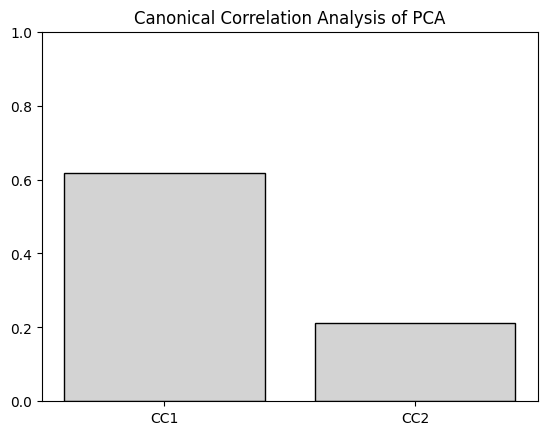

In [ ]:
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of PCA')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.6181957717259284, 0.2118293864436674]

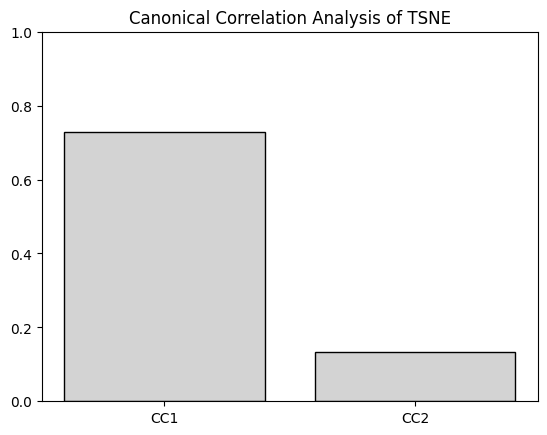

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(X_tsne, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(X_tsne, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of TSNE')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.7296871334158274, 0.13341316285734292]

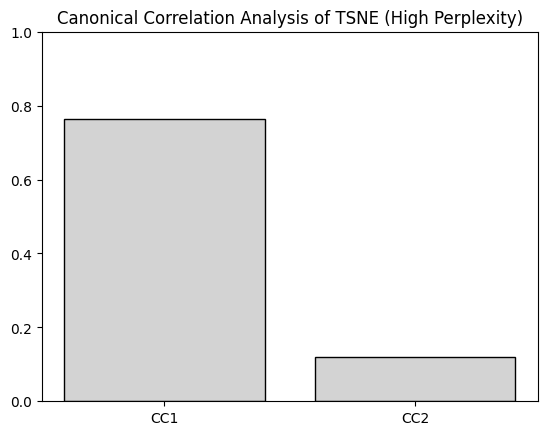

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(X_tsne_50, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(X_tsne_50, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of TSNE (High Perplexity)')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.7639975684441127, 0.11912760724654343]

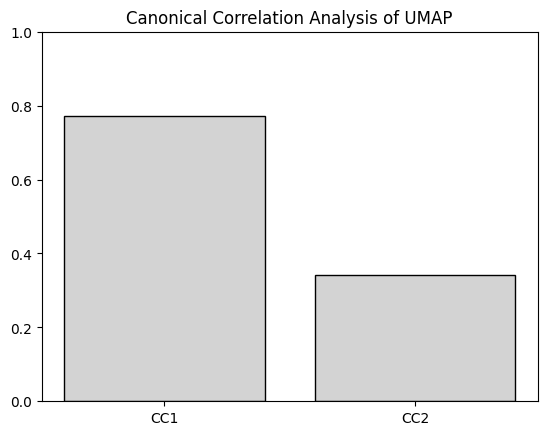

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(X_umap, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(X_umap, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of UMAP')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.7721646034591273, 0.34091763996669683]

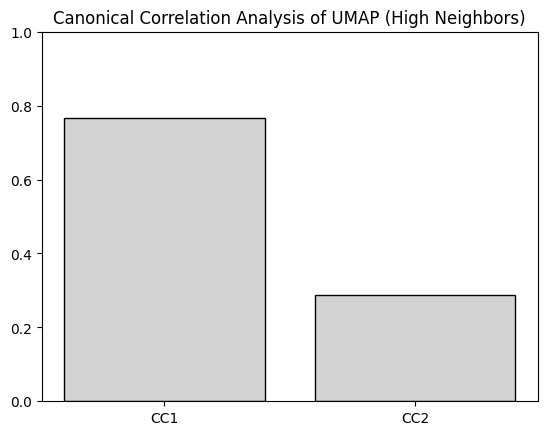

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(X_umap_50, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(X_umap_50, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of UMAP (High Neighbors)')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.7670806241260686, 0.2870840200789806]

### KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

In [ ]:
x_df = pd.DataFrame(Xs)
x_df['plate_group'] = plate_group
X_train, X_test = train_test_split(x_df, test_size=0.2, random_state=42)
plate_group_train = X_train['plate_group']
plate_group_test = X_test['plate_group']

In [ ]:
X_train, X_test = train_test_split(X_pca, test_size=0.2, random_state=42)
k=50
clf = KNeighborsClassifier(n_neighbors = 50)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.791704701049749, test score = 0.7882571558975028


In [ ]:
X_train, X_test = train_test_split(X_tsne, test_size=0.2, random_state=42)
clf = KNeighborsClassifier(n_neighbors = 50)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.9597623394405685, test score = 0.9613353328551868


In [ ]:
X_train, X_test = train_test_split(X_tsne_50, test_size=0.2, random_state=42)
clf = KNeighborsClassifier(n_neighbors = 50)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.9592896263936884, test score = 0.9605855121601357


In [ ]:
X_train, X_test = train_test_split(X_umap, test_size=0.2, random_state=42)
clf = KNeighborsClassifier(n_neighbors = 50)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.9530465540848927, test score = 0.9543913412010171


In [ ]:
X_train, X_test = train_test_split(X_umap_50, test_size=0.2, random_state=42)
clf = KNeighborsClassifier(n_neighbors = 50)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 50, training score = 0.9497131120818935, test score = 0.9497620134315707


### Plots

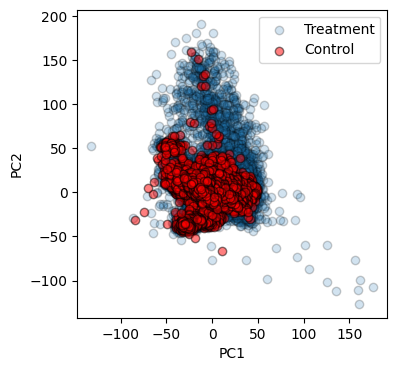

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_pca[X_meta[X_meta.columns[-1]]=='trt',0], X_pca[X_meta[X_meta.columns[-1]]=='trt',1], alpha = 0.2, ec = 'k', label='Treatment')
plt.scatter(X_pca[X_meta[X_meta.columns[-1]]=='control',0], X_pca[X_meta[X_meta.columns[-1]]=='control',1], alpha = 0.5, ec = 'k', color = 'red',label='Control')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

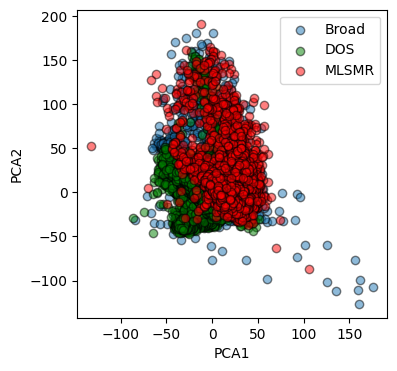

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k', label='Broad')
plt.scatter(X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green', label='DOS')
plt.scatter(X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_pca[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red', label='MLSMR')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.legend()
plt.show()

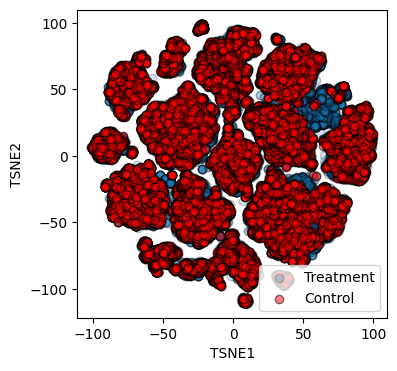

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_tsne[X_meta[X_meta.columns[-1]]=='trt',0], X_tsne[X_meta[X_meta.columns[-1]]=='trt',1], alpha = 0.2, ec = 'k', label='Treatment')
plt.scatter(X_tsne[X_meta[X_meta.columns[-1]]=='control',0], X_tsne[X_meta[X_meta.columns[-1]]=='control',1], alpha = 0.5, ec = 'k', color = 'red', label='Control')
plt.xlabel('TSNE1')
plt.ylabel('TSNE2')
plt.legend()
plt.show()

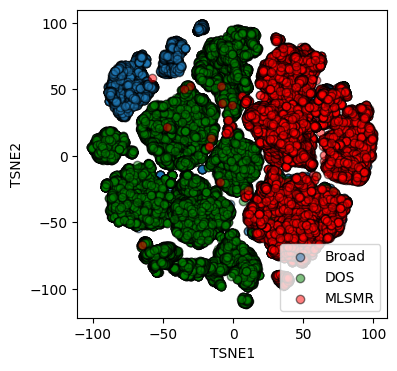

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k', label='Broad')
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green', label='DOS')
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red', label = 'MLSMR')
plt.xlabel('TSNE1')
plt.ylabel('TSNE2')
plt.legend()
plt.show()

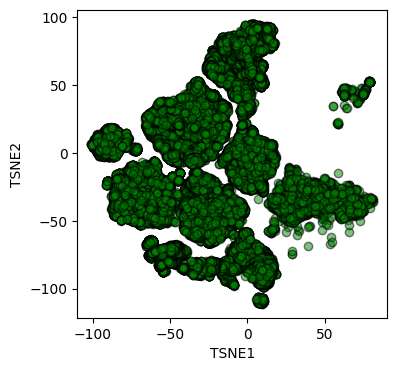

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('TSNE1')
plt.ylabel('TSNE2')
plt.show()

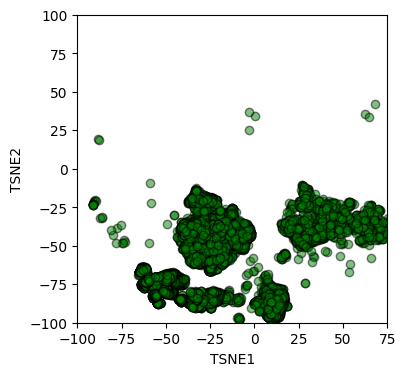

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('TSNE1')
plt.ylabel('TSNE2')
plt.xlim(-100, 75)
plt.ylim(-100, 100)
plt.show()

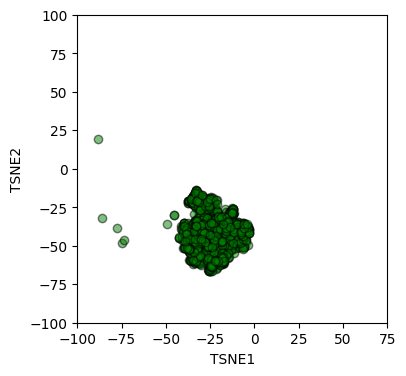

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',0], X_tsne[X_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('TSNE1')
plt.ylabel('TSNE2')
plt.xlim(-100, 75)
plt.ylim(-100, 100)
plt.show()

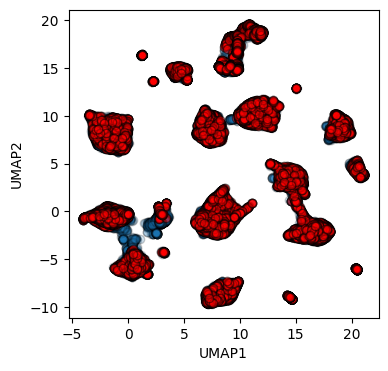

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_umap[X_meta[X_meta.columns[-1]]=='trt',0], X_umap[X_meta[X_meta.columns[-1]]=='trt',1], alpha = 0.2, ec = 'k')
plt.scatter(X_umap[X_meta[X_meta.columns[-1]]=='control',0], X_umap[X_meta[X_meta.columns[-1]]=='control',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.show()

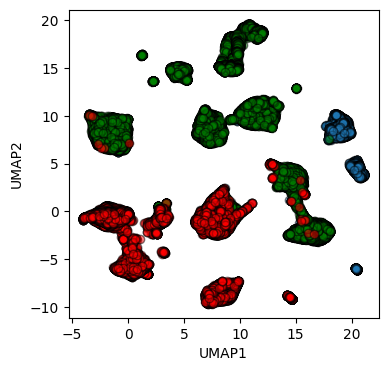

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green')
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.show()

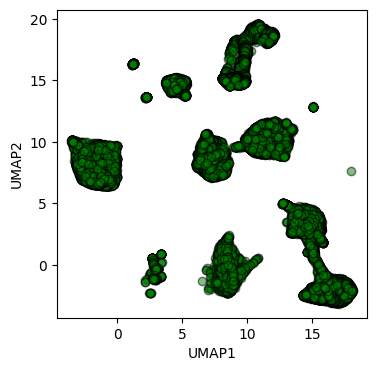

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.show()

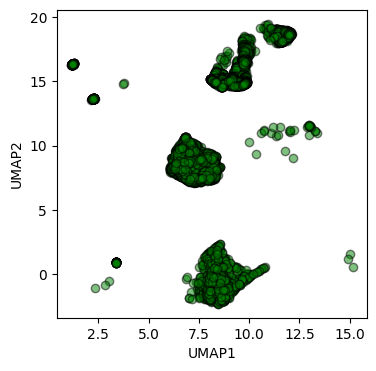

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',0], X_umap[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.show()

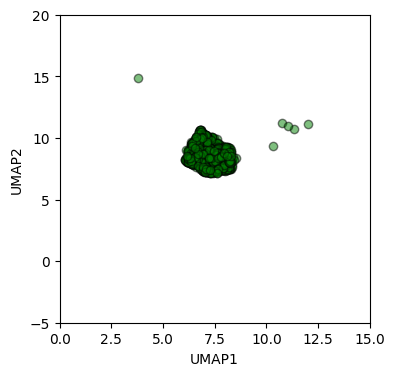

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(X_umap[X_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',0], X_umap[X_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.xlim(0, 15)
plt.ylim(-5, 20)
plt.show()

In [ ]:
plate_array = np.sort(X_meta['Metadata_Plate'].value_counts().index.values)

In [ ]:
plate_pca_1_mean = []
plate_pca_2_mean = []
for i in plate_array:
  plate_pca_1_mean.append(X_pca[X_meta['Metadata_Plate']==i,0].mean())
  plate_pca_2_mean.append(X_pca[X_meta['Metadata_Plate']==i,1].mean())

In [ ]:
plate_tsne_1_mean = []
plate_tsne_2_mean = []
for i in plate_array:
  plate_tsne_1_mean.append(X_tsne[X_meta['Metadata_Plate']==i,0].mean())
  plate_tsne_2_mean.append(X_tsne[X_meta['Metadata_Plate']==i,1].mean())

In [ ]:
plate_umap_1_mean = []
plate_umap_2_mean = []
for i in plate_array:
  plate_umap_1_mean.append(X_umap[X_meta['Metadata_Plate']==i,0].mean())
  plate_umap_2_mean.append(X_umap[X_meta['Metadata_Plate']==i,1].mean())

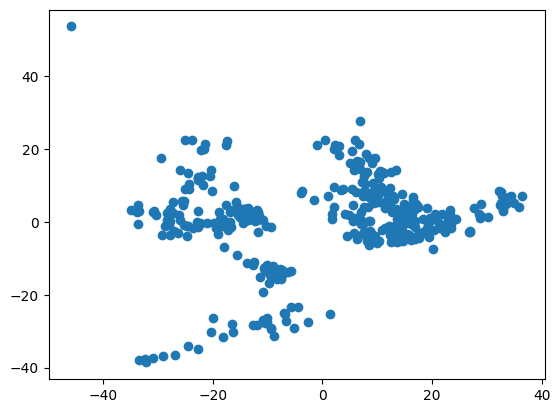

In [ ]:
plt.scatter(plate_pca_1_mean, plate_pca_2_mean)

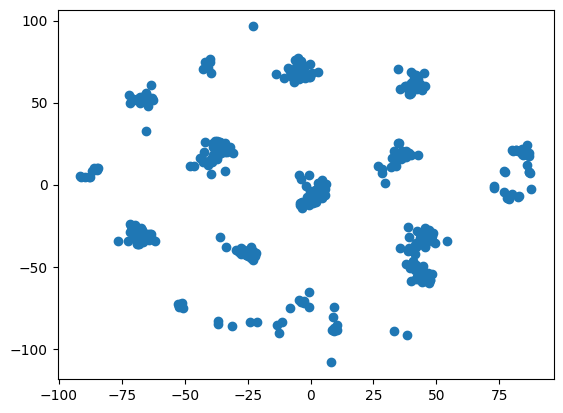

In [ ]:
plt.scatter(plate_tsne_1_mean, plate_tsne_2_mean)

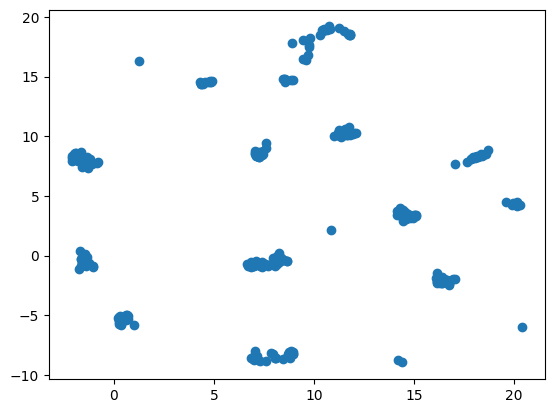

In [ ]:
plt.scatter(plate_umap_1_mean, plate_umap_2_mean)

In [ ]:
X_train, X_test = train_test_split(Xs, test_size=0.2, random_state=42)

In [ ]:
class Autoencoder(Model):
  def __init__(self, latent_dim, shape):
    super(Autoencoder, self).__init__()
    self.latent_dim = latent_dim
    self.shape = shape
    self.encoder = tf.keras.Sequential([
      layers.Dense(200, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(latent_dim, activation='tanh'),
    ])
    self.decoder = tf.keras.Sequential([
      layers.Dense(200, activation='tanh'),
      layers.Dropout(0.2),
      layers.Dense(tf.math.reduce_prod(shape).numpy(), activation='sigmoid'),
      layers.Reshape(shape)
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded


shape = X_test.shape[1:]
latent_dim = 2
autoencoder = Autoencoder(latent_dim, shape)

In [ ]:
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

In [ ]:
autoencoder.fit(X_train, X_train,
                epochs=5,
                shuffle=True,
                validation_data=(X_test, X_test))

Epoch 1/5
3835/3835 [==============================] - 27s 7ms/step - loss: 0.8351 - val_loss: 0.8006
Epoch 2/5
3835/3835 [==============================] - 27s 7ms/step - loss: 0.8101 - val_loss: 0.7918
Epoch 3/5
3835/3835 [==============================] - 27s 7ms/step - loss: 0.8045 - val_loss: 0.7869
Epoch 4/5
3835/3835 [==============================] - 27s 7ms/step - loss: 0.8007 - val_loss: 0.7838
Epoch 5/5
3835/3835 [==============================] - 26s 7ms/step - loss: 0.7979 - val_loss: 0.7803


In [ ]:
encoded_imgs = autoencoder.encoder(X_test).numpy()

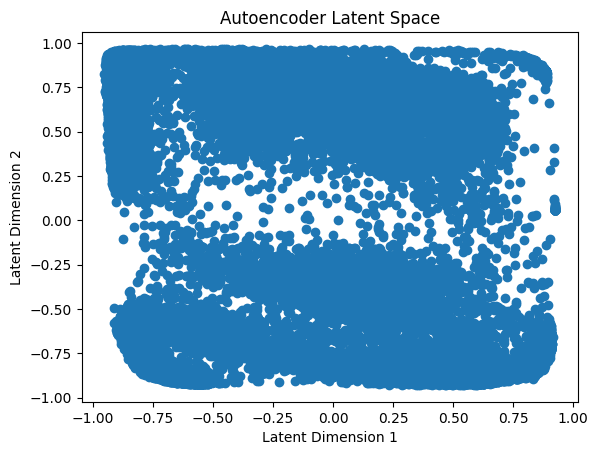

In [ ]:
plt.scatter(encoded_imgs[:, 0], encoded_imgs[:, 1])
plt.title('Autoencoder Latent Space')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

In [ ]:
X_train_meta, X_test_meta = train_test_split(X_meta, test_size=0.2, random_state=42)

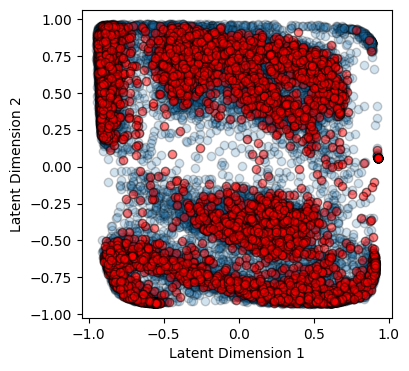

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(encoded_imgs[X_test_meta[X_test_meta.columns[-1]]=='trt',0], encoded_imgs[X_test_meta[X_test_meta.columns[-1]]=='trt',1], alpha = 0.2, ec = 'k')
plt.scatter(encoded_imgs[X_test_meta[X_test_meta.columns[-1]]=='control',0], encoded_imgs[X_test_meta[X_test_meta.columns[-1]]=='control',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

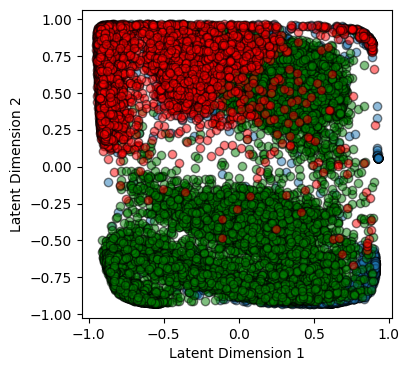

In [ ]:
plt.figure(figsize = (4, 4))
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green')
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

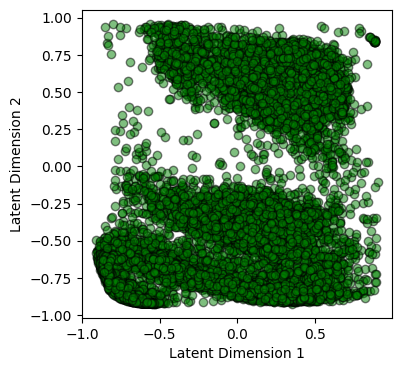

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

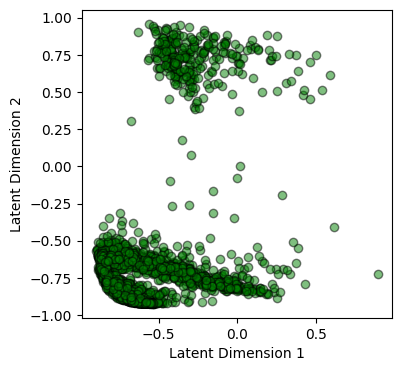

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[1]=='CBLE',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.show()

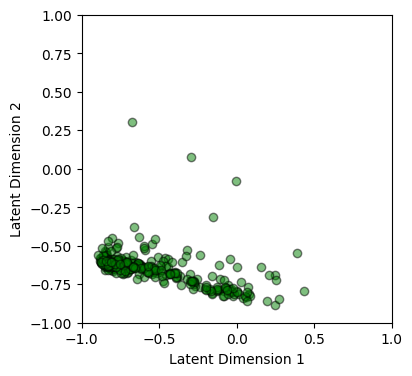

In [ ]:
plt.figure(figsize = (4, 4))
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[3]=='3',1], alpha = 0.5, ec = 'k')
plt.scatter(encoded_imgs[X_test_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',0], encoded_imgs[X_test_meta['Metadata_Plate_Map_Name']=='H-CBLE-001-4',1], alpha = 0.5, ec = 'k', color='green')
#plt.scatter(X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',0], X_tsne[X_meta['Metadata_Plate_Map_Name'].str.split('-', expand=True)[0]=='C',1], alpha = 0.5, ec = 'k', color = 'red')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.show()

In [ ]:
X_train_2, X_test_2 = train_test_split(X, test_size=0.2, random_state=42)

In [ ]:
one_hot_encoded_data = pd.get_dummies(X_test_2, columns = ['plate_group'])

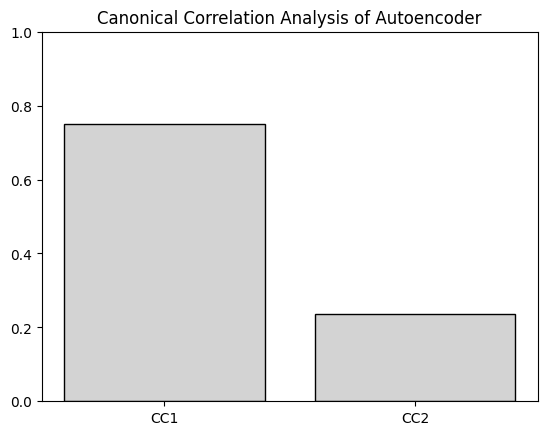

In [ ]:
cca = CCA(scale = False, n_components=2)
cca.fit(encoded_imgs, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
W, Q = cca.transform(encoded_imgs, one_hot_encoded_data[['plate_group_DOS', 'plate_group_Broad', 'plate_group_MLSMR']])
comp_corr = [np.corrcoef(W[:, i], Q[:, i])[1][0] for i in range(2)]
plt.bar(['CC1', 'CC2'], comp_corr, color='lightgrey', width = 0.8, edgecolor='k')
plt.title('Canonical Correlation Analysis of Autoencoder')
plt.ylim(0,1)
plt.show()

In [ ]:
comp_corr

[0.7513541999738137, 0.23736096022736905]

In [ ]:
plate_group = []
for i in X_test_meta['Metadata_Plate_Map_Name']:
  if(i.split('-')[0]=='C'):
    plate_group.append("MLSMR")
  elif(i.split('-')[3]=='3'):
    plate_group.append("Broad")
  else:
    plate_group.append("DOS")

In [ ]:
plate_group_train, plate_group_test = train_test_split(plate_group, test_size=0.2, random_state=42)
X_train, X_test = train_test_split(encoded_imgs, test_size=0.2, random_state=42)
k=30
clf = KNeighborsClassifier(n_neighbors = k)
clf.fit(X_train, plate_group_train)
training_score = clf.score(X_train, plate_group_train)
test_score = clf.score(X_test, plate_group_test)
print(f'k = {k}, training score = {training_score}, test score = {test_score}')

k = 30, training score = 0.9034190472309385, test score = 0.8995925020374899
